In [ ]:
import sys
project_root = "../.."
sys.path.append(project_root)

import seaborn as sns
import torch
from IPython.display import HTML
import matplotlib.pyplot as plt

# Import project packages
from src.simulation.visualization.animation import create_animation_2d
from src.simulation.equations.advdiff2d import AdvectionDiffusionEquation2D 

device = torch.device("cpu")
sns.set_style("ticks")
sns.set_context("paper")

In [ ]:
eq = AdvectionDiffusionEquation2D(
    Lx=1.0, Ly=1.0, T=1.0, n_x=64, n_y=64, n_t=99,
    velocity={"v_x":+0.1, "v_y":0.5},
    diffusivity={"type":"constant","value":0.00},
    ic={"type":"grf", "ell": 0.03, "normalize": True},
    CFL=0.5, second_order=True,
    bc={"type":"Periodic"},
    advection_scheme="fdm2_euler_fixed",
)

snapshots = eq.solve()

frames = [snapshots[i] for i in range(len(snapshots))]
animation = create_animation_2d(frames, colormap="viridis", vmin=snapshots.min(), vmax=snapshots.max())
HTML(animation.to_html5_video())

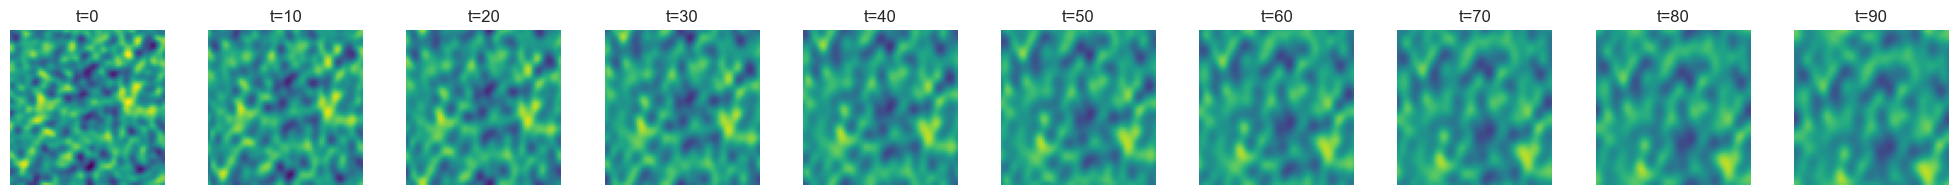

In [3]:

n_snapshots = len(snapshots)
step = 10
num_plots = n_snapshots // step
fig, axes = plt.subplots(1, num_plots, figsize=(2*num_plots, 2))

if num_plots == 1:
    axes = [axes]

for i, idx in enumerate(range(0, n_snapshots, step)):
    ax = axes[i]
    img = ax.imshow(snapshots[idx], cmap="viridis", vmin=snapshots.min(), vmax=snapshots.max())
    ax.set_title(f"t={idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()